# M2 · 05 — Train / Validation / Test Split (leak-free)

The dataset ships with a single `test` split, so we build our own **70 / 15 / 15** split with `src/medibridge/split.py`.

**What "leak-free" means here:**
1. **No session in two splits.** Clips from one recording session share a speaker, a patient story and vocabulary. A `hi` conversation session has up to 24 clips.
2. **No identical or near-identical transcript in two splits.** Rows sharing a session *or* a normalised transcript are joined into one group (union-find), and whole groups are assigned.
3. **Stratified by recording context.** Each split gets the same mix of conversations and narrations.

Assignment is greedy and deterministic (seed 42): the largest groups are placed first, each into the split furthest below its target size.

In [1]:
# Requires the project package: `pip install -e ".[analysis]"` from the repository root.
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from medibridge.config import PROCESSED_DIR, SPLITS, SUBSETS
from medibridge.io import load_all_splits
from medibridge.split import leak_groups, leakage_report

In [2]:
sns.set_theme(style="whitegrid", context="notebook", palette="deep")
FIG = Path("figures")
FIG.mkdir(exist_ok=True)
pd.set_option("display.max_colwidth", 110)
pd.set_option("display.width", 160)

data = {s: load_all_splits(s) for s in SUBSETS}
report = json.loads((PROCESSED_DIR / "split_report.json").read_text())

## 1. Split sizes

In [3]:
sizes = pd.DataFrame(
    {(s, k): pd.Series(report[s][k]) for s in SUBSETS for k in ("rows", "sessions", "entities")}
).T
sizes["train %"] = (sizes["train"] / sizes[list(SPLITS)].sum(axis=1) * 100).round(1)
sizes

train   val  test  train %
hi rows        221    48    47     69.9
   sessions    139    32    32     68.5
   entities   1195   253   285     69.0
en rows       2329   500   498     70.0
   sessions   2276   493   491     69.8
   entities   7244  1561  1504     70.3

In [4]:
pd.concat({s: pd.DataFrame(report[s]["rows_by_context"]).T for s in SUBSETS})

conversation  narration_sentence  narration_entity
hi train            88                 133               NaN
   val              19                  29               NaN
   test             19                  28               NaN
en train            76                 884            1369.0
   val              17                 190             293.0
   test             16                 189             293.0

## 2. Leakage checks (must all be 0)

In [5]:
leak = pd.concat({s: pd.DataFrame(leakage_report(data[s])) for s in SUBSETS}, axis=1)
display(leak)
assert (leak.values == 0).all(), "leakage found!"
print("✓ no session, exact-text or normalised-text overlap between any two splits")

hi                                    en                           
           session_id exact_text normalised_text session_id exact_text normalised_text
train-val           0          0               0          0          0               0
train-test          0          0               0          0          0               0
val-test            0          0               0          0          0               0

✓ no session, exact-text or normalised-text overlap between any two splits


In [6]:
groups = {s: leak_groups(data[s]) for s in SUBSETS}
for s, d in data.items():
    g = groups[s]
    crossing = d.assign(g=g).groupby("g")["split"].nunique().gt(1).sum()
    print(
        f"{s}: {g.nunique()} leak-groups, largest has {g.value_counts().max()} rows, groups spanning >1 split: {crossing}"
    )

hi: 203 leak-groups, largest has 24 rows, groups spanning >1 split: 0
en: 3260 leak-groups, largest has 7 rows, groups spanning >1 split: 0


## 3. Are the splits representative? (entity-type distribution, χ²)
**H0:** entity-type proportions are the same in train, validation and test.

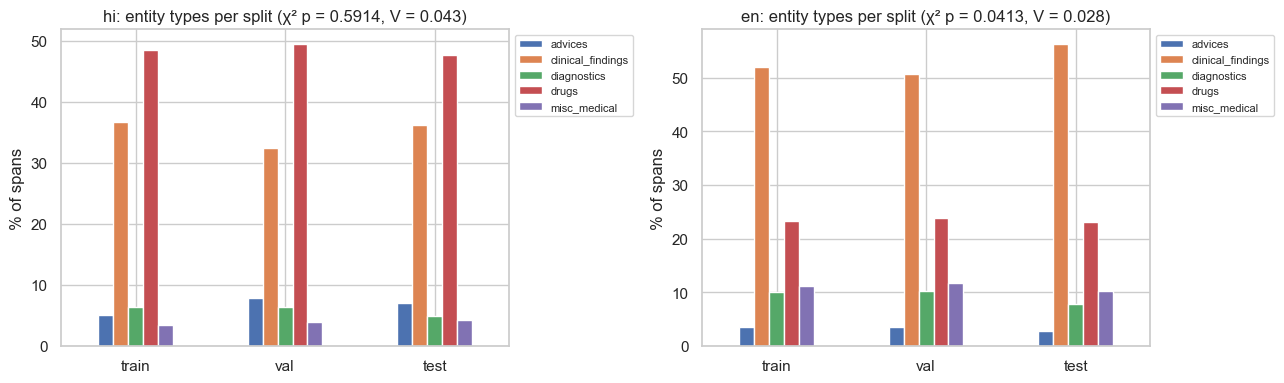

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, s in zip(axes, ("hi", "en")):
    t = pd.DataFrame(report[s]["entity_types"]).T.reindex(list(SPLITS))
    (t.T / t.sum(axis=1)).T.mul(100).plot.bar(ax=ax, rot=0)
    chi = report[s]["type_distribution_chi2"]
    ax.set(
        title=f"{s}: entity types per split (χ² p = {chi['p_value']}, V = {chi['cramers_v']:.3f})",
        ylabel="% of spans",
        xlabel="",
    )
    ax.legend(fontsize=8, loc="upper left", bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.savefig(FIG / "08_split_types.png", dpi=150)
plt.show()

For `hi`, p > 0.05: we cannot reject H0, so the splits are representative. For `en`, the test detects a small difference because the sample is large (over 10k spans), but Cramér's V shows the effect size is negligible.

## 4. Speaker overlap (known limitation)

In [8]:
for s, d in data.items():
    known = d[d.speaker != "unknown"]
    sets = {sp: set(known.loc[known.split == sp, "speaker"]) for sp in SPLITS}
    print(
        f"{s}: {known.speaker.nunique()} known speakers; shared train∩test: {len(sets['train'] & sets['test'])}; rows with unknown speaker: {(d.speaker == 'unknown').sum()}"
    )

hi: 5 known speakers; shared train∩test: 4; rows with unknown speaker: 126
en: 56 known speakers; shared train∩test: 49; rows with unknown speaker: 109


The `hi` subset has only 5 known speakers, so a speaker-disjoint split is impossible. This doesn't affect text NER much, because the text varies more than the speakers do. It matters for **speech** (M5), where we will report results per speaker. We state this in the data card as a threat to validity.

## 5. How to load the splits (for M3)

In [9]:
from medibridge.io import load_split

train = load_split("hi", "train")
print(train.shape)
train[["id", "text", "context", "n_entities", "cmi"]].head(3)

(221, 20)


,id,text,context,n_entities,cmi
0,942d0c98d850b1d5f471c17130643e89,"समझ गया । किसके कारण होगा ये? It could be stress related or migraine,अच्छा। Make sure you are hydrating yo...",conversation,6,42.22
1,ba9a0ff550fb08e13cb629da745e9bdf,बंद नहीं हुआ है । और इसके साथ बुखार या उल्टी कुछ हो रहा है? नहीं नहीं । थोड़ा सा,conversation,2,0.00
2,d1d9e9c9dea3410445cbd57215abe112,"अच्छा, कितना सीवियर हो रहा है आपको सर दर्द? आज तो बहुत ज्यादा हो रहा है । बट इन जनरल मुझे ऐसे कभी ना कभी ह...",conversation,2,0.00


In [10]:
print((PROCESSED_DIR / "bio" / "hi_train.conll").read_text(encoding="utf-8")[:400])

# id = 942d0c98d850b1d5f471c17130643e89
समझ	O
गया	O
।	O
किसके	O
कारण	O
होगा	O
ये	O
?	O
It	O
could	O
be	O
stress	B-clinical_findings
related	O
or	O
migraine	B-clinical_findings
,	O
अच्छा	O
।	O
Make	O
sure	O
you	O
are	O
hydrating	B-advices
yourself	O
well	O
और	O
आप	O
अच्छी	O
तरह	O
से	O
खाना	B-advices
टाइम	I-advices
पे	I-advices
खा	O
रहे	O
हो	O
।	O
नींद	B-advices
अटलीस्ट	I-advices
6	I-advices
टू	I-ad
